In [73]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

## Il braccio robotico

Consideriamo un braccio robotico planare formato da due segmenti rigidi di lunghezza $L_1=2$ e $L_2=1.5$.

Il primo segmento può ruotare attorno alla base di un angolo $\theta_1$, mentre il secondo può ruotare rispetto al primo di un angolo $\theta_2$.

Supponiamo che all'estremità del secondo segmento si trovi una calamita.

*Conoscendo $\theta_1$ e $\theta_2$, dove si trova la calamita?*

Possiamo descrivere ciascun segmento come un vettore.

Per il primo segmento:

$$
\mathbf{v}_1 =
\begin{pmatrix}
L_1\cos(\theta_1)\\
L_1\sin(\theta_1)
\end{pmatrix}.
$$

Il punto $P_1$, corrispondente al primo giunto, si trova quindi in $\overrightarrow{OP_1}=\mathbf{v}_1$

Il secondo segmento forma un angolo complessivo $\theta_1+\theta_2$ rispetto all'asse $x$:

$$
\mathbf{v}_2 =
\begin{pmatrix}
L_2\cos(\theta_1+\theta_2)\\
L_2\sin(\theta_1+\theta_2)
\end{pmatrix}.
$$

La posizione $P_2$ della calamita è quindi

$$
\overrightarrow{OP_2}=\mathbf{v}_1+\mathbf{v}_2.
$$


In [71]:
L1 = 2
L2 = 1.5

theta1 = np.radians(30)
theta2 = np.radians(50)

v1 = np.array([L1*np.cos(theta1),
               L1*np.sin(theta1)])

v2 = np.array([L2*np.cos(theta1 + theta2),
               L2*np.sin(theta1 + theta2)])

p1 = v1
p2 = v1 + v2

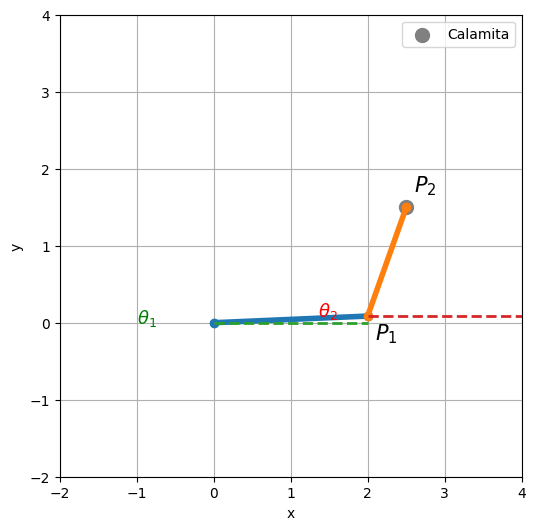

In [85]:
fig, ax = plt.subplots(figsize=(6, 6))

# Braccio robotico
ax.plot([0, p1[0]], [0, p1[1]], "o-", linewidth=4)
ax.plot([p1[0], p2[0]], [p1[1], p2[1]], "o-", linewidth=4)

# Calamita
ax.scatter(p2[0], p2[1], s=100, label="Calamita", color="grey")

# Etichette punti
ax.text(p1[0] + 0.1, p1[1] - 0.3, r"$P_1$", fontsize=15)
ax.text(p2[0] + 0.1, p2[1] + 0.2, r"$P_2$", fontsize=15)

# Asse di riferimento per theta_1
ax.plot([0, 2], [0, 0], "--", linewidth=2)

# Prolungamento del primo segmento per mostrare theta_2
direction1 = np.array([np.cos(theta1), np.sin(theta1)])
extension = p1 + 2 * direction1
ax.plot([p1[0], extension[0]], [p1[1], extension[1]], "--",linewidth=2)

# Etichette angoli
ax.text(np.cos(theta1/2),np.sin(theta1/2), r"$\theta_1$", fontsize=13, color="green")
ax.text(p1[0] + 0.65*np.cos(theta1 + theta2 / 2), p1[1] + 0.65*np.sin(theta1 + theta2 / 2), r"$\theta_2$", fontsize=13, color="red")

ax.set_xlim(-2, 4)
ax.set_ylim(-2, 4)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid()
ax.set_aspect("equal")
ax.legend()

plt.show()

## Quali punti può raggiungere il robot?

Finora abbiamo scelto due angoli $\theta_1$ e $\theta_2$ e abbiamo calcolato la posizione della calamita.

Proviamo ora a variare entrambi gli angoli e osserviamo le posizioni che la calamita può raggiungere.

In [ ]:
theta1_values = np.linspace(0, 2*np.pi, 25)
theta2_values = np.linspace(0, 2*np.pi, 25)

configurations = []

for t1 in theta1_values:
    for t2 in theta2_values:
        configurations.append((t1, t2))

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.set_xlim(-(L1 + L2 + 0.5), L1 + L2 + 0.5)
ax.set_ylim(-(L1 + L2 + 0.5), L1 + L2 + 0.5)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.grid()

# Braccio robotico
arm, = ax.plot([], [], "o-", linewidth=3)

# Traccia lasciata dalla calamita
trace, = ax.plot([], [], ".", markersize=2)

trace_x = []
trace_y = []


def update(frame):

    theta1, theta2 = configurations[frame]

    # Posizione del primo giunto
    x1 = L1 * np.cos(theta1)
    y1 = L1 * np.sin(theta1)

    # Posizione dell'estremità
    x2 = x1 + L2 * np.cos(theta1 + theta2)
    y2 = y1 + L2 * np.sin(theta1 + theta2)

    # Aggiorna il braccio
    arm.set_data([0, x1, x2], [0, y1, y2])

    # Aggiungi la posizione finale alla traccia
    trace_x.append(x2)
    trace_y.append(y2)
    trace.set_data(trace_x, trace_y)

    return arm, trace


animation = FuncAnimation(
    fig,
    update,
    frames=len(configurations),
    interval=15,
    blit=True)

plt.close()

HTML(animation.to_jshtml())

Supponiamo ora di conoscere la posizione di un oggetto posto in $P_A=(2.5,1.5)$ e di voler determinare come muovere il robot.

Per raggiungere un punto $P=(x,y)$ dobbiamo trovare due angoli $\theta_1$ e $\theta_2$ tali che

$$
\begin{cases}
x =
L_1\cos(\theta_1)
+
L_2\cos(\theta_1+\theta_2)
\\
y =
L_1\sin(\theta_1)
+
L_2\sin(\theta_1+\theta_2).
\end{cases}
$$

Quindi conosciamo $x$ e $y$, mentre le incognite sono gli angoli. 

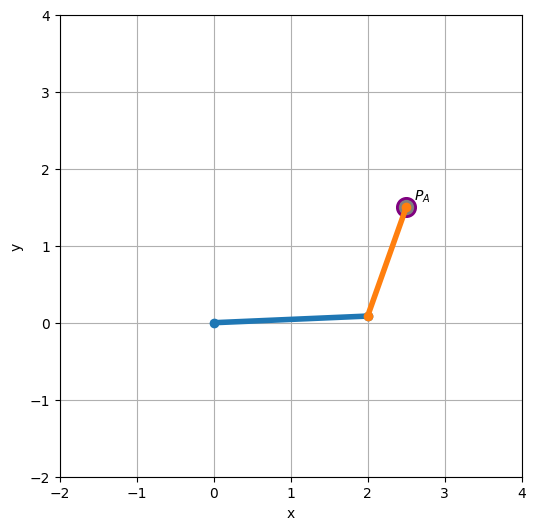

In [86]:
target_A = np.array([2.5, 1.5])


plt.figure(figsize=(6, 6))

plt.plot([0, p1[0]], [0, p1[1]], "o-", linewidth=4)
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], "o-", linewidth=4)
plt.scatter(target_A[0], target_A[1], s=200, label=r"$P_A$", color="purple")
plt.scatter(p2[0], p2[1], s=100, label="Calamita", color="grey")


plt.text(target_A[0] + 0.1, target_A[1] + 0.1, r"$P_A$")

plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.grid()
plt.xlim(-2, 4)
plt.ylim(-2, 4)

plt.show()

Il sistema contiene due equazioni e due incognite, ma le incognite compaiono all'interno di seni e coseni: è quindi un sistema non lineare. Non possiamo risolverlo con l'eliminazione di Gauss, ma possiamo cercarne numericamente una soluzione.

In [69]:
from scipy.optimize import root

target = target_A

def equations(theta):
    theta1, theta2 = theta

    x = L1*np.cos(theta1) + L2*np.cos(theta1 + theta2)
    y = L1*np.sin(theta1) + L2*np.sin(theta1 + theta2)

    return [x - target[0], y - target[1]]


solution = root( equations, x0=[0, 1])

theta1_sol, theta2_sol = solution.x

print(f" θ1 = {np.degrees(theta1_sol):.0f} gradi")
print(f" θ2 = {np.degrees(theta2_sol):.0f} gradi")

 θ1 = 2 gradi
 θ2 = 68 gradi


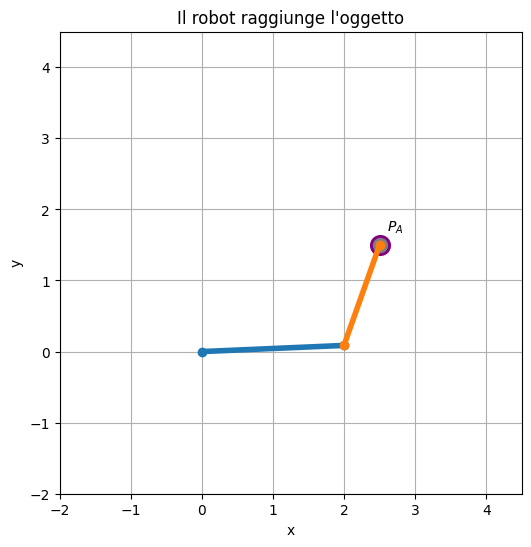

In [ ]:
v1 = np.array([ L1*np.cos(theta1_sol),
                L1*np.sin(theta1_sol) ])

v2 = np.array([ L2*np.cos(theta1_sol + theta2_sol),
                L2*np.sin(theta1_sol + theta2_sol) ])

p1 = v1
p2 = v1 + v2

plt.figure(figsize=(6, 6))
plt.plot([0, p1[0]], [0, p1[1]], "o-", linewidth=4)
plt.plot([p1[0], p2[0]], [p1[1], p2[1]], "o-", linewidth=4)
plt.scatter(target[0], target[1], s=200, color="purple")
plt.scatter(p2[0], p2[1], s=100, label="Calamita", color="grey")

plt.text(target[0] + 0.1, target[1] + 0.2, r"$P_A$")

plt.xlim(-2, 4.5)
plt.ylim(-2, 4.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Il robot raggiunge l'oggetto")
plt.gca().set_aspect("equal")
plt.grid()

plt.show()

La soluzione è unica? In generale no: lo stesso punto può essere raggiunto con configurazioni diverse del braccio

Soluzione 1: [ 2.47734455 67.97568716]
Soluzione 2: [ 59.45016851 -67.97568716]


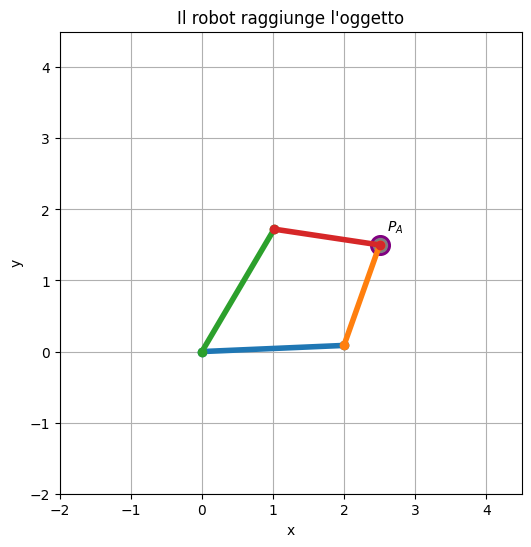

In [ ]:
solution_1 = root(equations, x0=[0, 1])
solution_2 = root(equations, x0=[1, -1])

print("Soluzione 1:", np.degrees(solution_1.x))
print("Soluzione 2:", np.degrees(solution_2.x))

theta1_sol1, theta2_sol1 = solution_1.x
v1_1 = np.array([ L1*np.cos(theta1_sol1),
                L1*np.sin(theta1_sol1) ])
v2_1 = np.array([ L2*np.cos(theta1_sol1 + theta2_sol1),
                L2*np.sin(theta1_sol1 + theta2_sol1) ])
p1_1 = v1_1
p2_1 = v1_1 + v2_1

theta1_sol2, theta2_sol2 = solution_2.x
v1_2 = np.array([ L1*np.cos(theta1_sol2),
                L1*np.sin(theta1_sol2) ])
v2_2 = np.array([ L2*np.cos(theta1_sol2 + theta2_sol2),
                L2*np.sin(theta1_sol2 + theta2_sol2) ])
p1_2 = v1_2
p2_2 = v1_2 + v2_2

plt.figure(figsize=(6, 6))

plt.plot([0, p1_1[0]], [0, p1_1[1]], "o-", linewidth=4)
plt.plot([p1_1[0], p2_1[0]], [p1_1[1], p2_1[1]], "o-", linewidth=4)
plt.scatter(target[0], target[1], s=200, color="purple")
plt.scatter(p2_1[0], p2_1[1], s=100, label="Calamita", color="grey")

plt.plot([0, p1_2[0]], [0, p1_2[1]], "o-", linewidth=4)
plt.plot([p1_2[0], p2_2[0]], [p1_2[1], p2_2[1]], "o-", linewidth=4)

plt.text(target[0] + 0.1, target[1] + 0.2, r"$P_A$")

plt.xlim(-2, 4.5)
plt.ylim(-2, 4.5)
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.grid()

plt.show()